rumz
# Notebook for processing layers in ice
### May 25
#### V. 1.1

This notebook processes hyperspectral images of ice and extracts information in regards to climate proxies.
To run:
- ensure datasetPath points to the correct directory file
- Insert DataID for whichever core to be run

In [1]:
import warnings
import sys
import os
import datetime

# Add the processing folder to the Python path
processing_path = os.path.abspath(os.path.join('..', 'processing'))
if processing_path not in sys.path:
    sys.path.append(processing_path)

#Importing Python Libraries and Packages
import pandas as pd
import numpy as np
import set_icespec_path as tool
import set_bubbles_path as tool2
icespec_code_path=tool.add_icespec_code_dir()
bubble_code_path=tool2.add_bubble_code_dir()
tool.add_icespec_code_dir()
tool2.add_bubble_code_dir()
from icespec import icespec_process2_module as processice
from bubbles import bubbles_process_module as processbubbles
from Sums import sums_process_module as processSums
from icespec import savePNG
from icespec import ageConversion

### Users should fill in variables with desired core info
Use HSI_Jan2024 Spreadsheet for ID and section names

Debug variable prints more information during processing

In [2]:
datasetPath = '/data/icecores/HSI_Jan2024.csv' #path to csv file on computer or server

outputDir = '/data/icecores/Output' #png output path

DataID = "HSIUM-457" #insert DataID from excel file inside quotation marks

Debug = False
Save = True
SCRIPT_ID = "DENLayerSumNB"

In [3]:
dataPath, top_depth, bottom_depth, core_length, save_path, px_dims, metadata = processice.getDataPath(datasetPath, DataID, outputDir)

outputPath = processice.make_dir(save_path, SCRIPT_ID, metadata)
#outputPath = outputPath / DataID
print("Output Path: ", outputPath)

%matplotlib ipympl
data_nparr, w_ref, d_ref, wvls, fwhm = processice.getEnviData(dataPath)

Core:  DEN13A
Section:  228
Lighting: Top light - 50%, Bottom Light - 100%
Exposure:  4
Top Depth:  208.635
Bottom Depth:  209.18
Length =  0.5450000000000159
Dimensions:  1288, 4730, 3, 511
Output Path:  /data/icecores/Output/AL/DEN/DEN13A/DEN13A-228/2025-08-09_213147
<class 'numpy.ndarray'>


In [4]:
segment_boundaries, px_per_cm = processbubbles.get_segments(data_nparr, top_depth, bottom_depth, end_px=px_dims[1])
print("cm per px: ", px_per_cm)

#dataSize = [1500, 6600, 200, 900] #fill in based on interactive plot
dataSize = 	px_dims
stdSize = [248, 580, 200, 900] #standard sizing

cm per px:  64.77064220183297


The new dimensions will be: 311x3442
Trimmed shapes: (3442, 311, 224), W_ref: (116, 311, 224), D_ref: (100, 311, 224)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


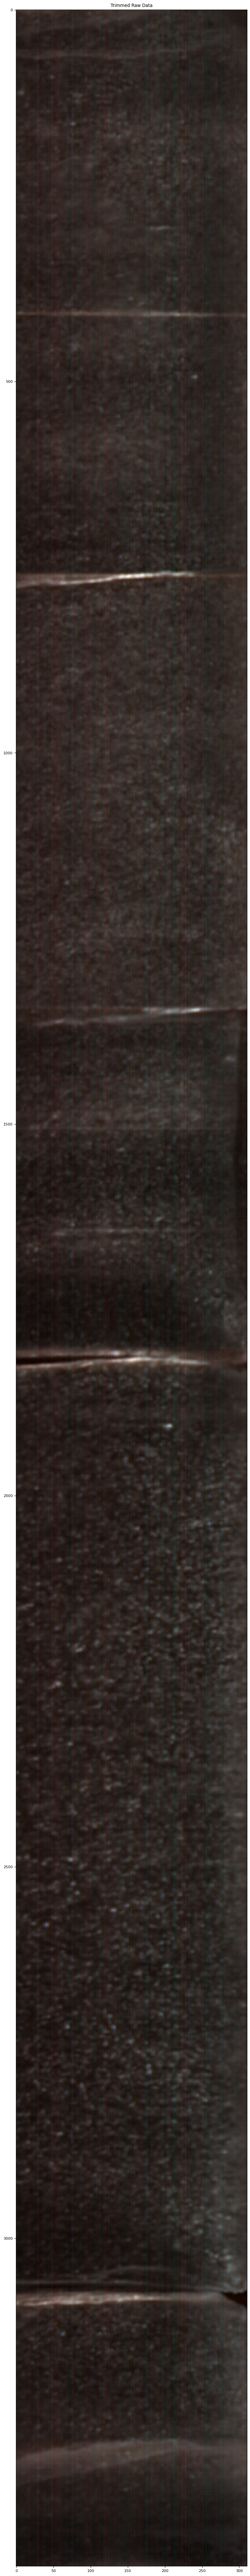

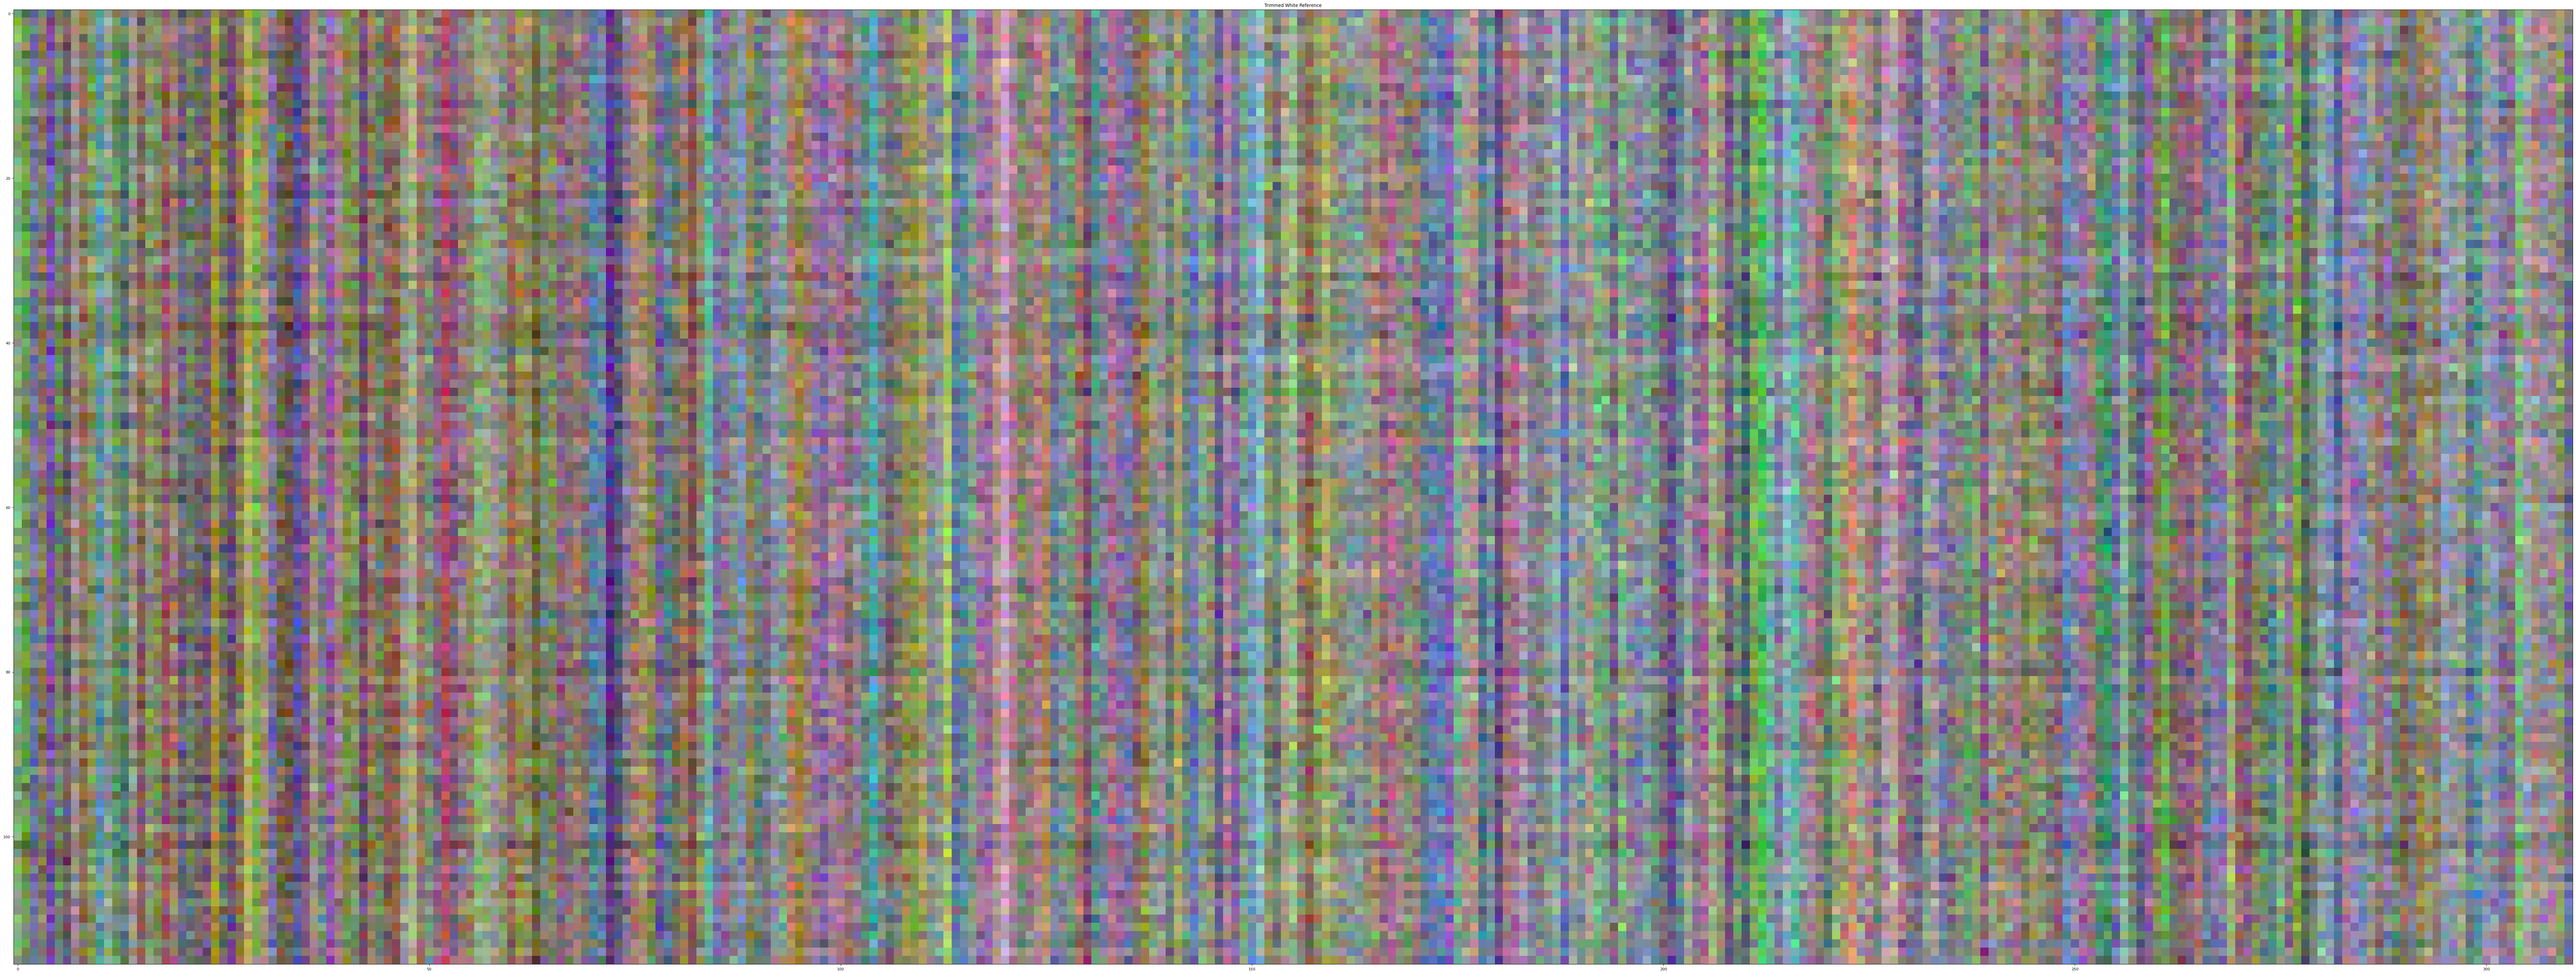

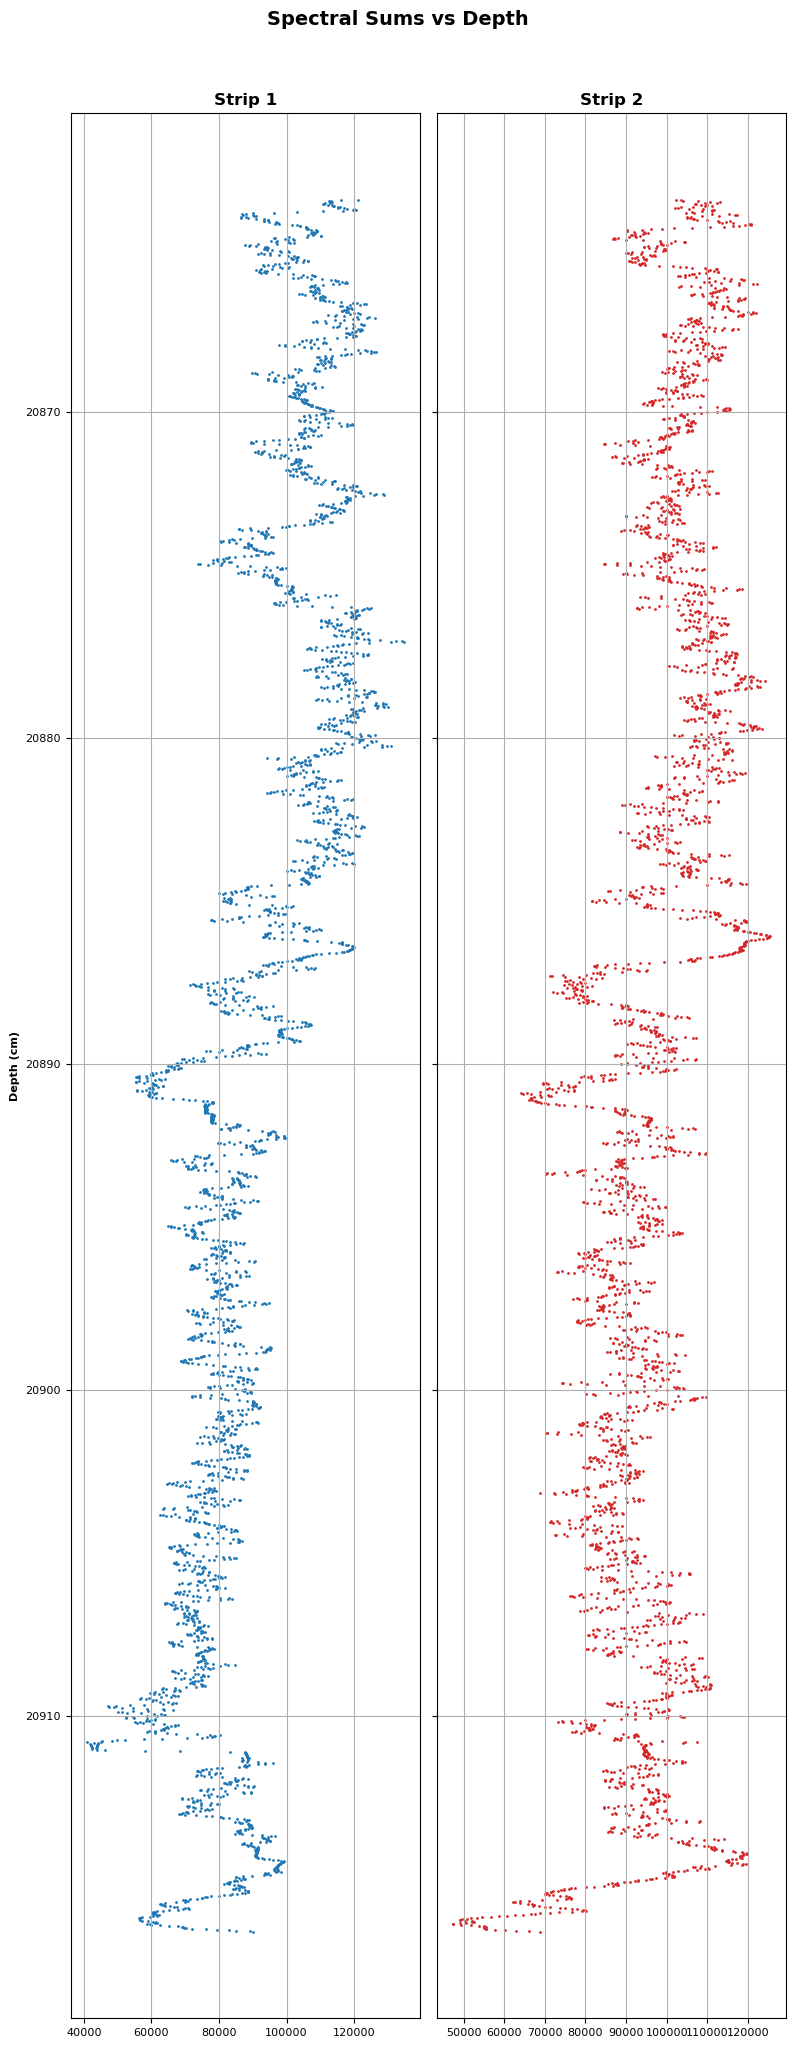

In [5]:
%matplotlib inline
trimmedData = processice.trim(data_nparr, w_ref, d_ref, dataSize, stdSize, Debug=True) #return arr of 3 trimmed
correctedData = processice.reflectance(trimmedData, Debug)
correctedData = np.clip(correctedData, 0, None)
#filtered_img, fwhm = processice.remove_bands(correctedData, trimmedData[1], fwhm)

inpainted_img = processice.bubbles(correctedData,  fwhm)

imgSums = processSums.sum_comparison(inpainted_img, px_per_cm, top_depth, Debug, True, outputPath)